In [1]:

import os
import random
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import time



In [2]:
SEED = 0          # même graine que 1-Prepocessing : découpage identique
D = 64            # dimension de représentation, IDENTIQUE pour la PCA et l'AE
TEST_SIZE = 0.2   # part de cellules en validation
BATCH_SIZE = 128


In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

pd.set_option("display.width", 200)

repertoire = os.getcwd()
DATA_DIR = os.path.dirname(repertoire)

In [4]:
train = sc.read_h5ad(f"{repertoire}/data/train.h5ad")
val = sc.read_h5ad(f"{repertoire}/data/val.h5ad")


In [5]:
Xt = train.X
Xv = val.X

if sp.issparse(Xt):
    X_train = Xt.toarray()
else:
    X_train = Xt
X_train = np.asarray(X_train, dtype = np.float32)

if sp.issparse(Xv):
    X_val = Xv.toarray()
else:
    X_val = Xv
X_val = np.asarray(X_val, dtype = np.float32)

print(X_train)
print(X_train.shape)
print(X_val.shape)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         1.441046  ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.07017838 0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.39168957 ... 0.         0.         0.39168957]]
(13105, 3000)
(3277, 3000)


## Structure du réseaux


In [6]:
N_EPOCHS = 200
LR = 1e-3



class Autoencodeur(nn.Module):
    def __init__(self, n, d):
        super().__init__()
        self.encodeur = nn.Sequential(
            nn.Linear(n, d),
            nn.Tanh(),
        )
        self.decodeur = nn.Sequential(
            nn.Linear(d, n),
        )

    def forward(self, x):
        return self.decodeur(self.encodeur(x))

    def encode(self, x):
        return self.encodeur(x)



n = X_train.shape[1]
net = Autoencodeur(n, D)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=LR)

X_train_t = torch.from_numpy(X_train)
X_val_t = torch.from_numpy(X_val)

loader = DataLoader(
    TensorDataset(X_train_t),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)


### AE profond


In [7]:
class AutoencodeurProfond(nn.Module):
    def __init__(self, n, d, couches=(512, 128)):
        super().__init__()

        # encodeur : n -> couches[0] -> couches[1] -> ... -> d
        enc, prev = [], n
        for h in couches:
            enc += nn.Linear(prev, h), nn.ReLU()
            prev = h
        enc += [nn.Linear(prev, d), nn.Tanh()]      # goulot
        self.encodeur = nn.Sequential(*enc)

        # décodeur symétrique : d -> ... -> couches[0] -> n
        dec, prev = [], d
        for h in reversed(couches):
            dec += nn.Linear(prev, h), nn.ReLU()
            prev = h
        dec += [nn.Linear(prev, n)]                 # sortie linéaire
        self.decodeur = nn.Sequential(*dec)

    def forward(self, x):
        return self.decodeur(self.encodeur(x))

    def encode(self, x):
        return self.encodeur(x)





## Entrainement

In [8]:
def train_session(net, loader, X_val_t, criterion, optimizer, n_epochs, print_every=20):
    hist = {"train": [], "val": []}
    for epoch in range(n_epochs):
        net.train()
        cumul, n_vus = 0.0, 0
        for (batch,) in loader:
            optimizer.zero_grad()
            perte = criterion(net(batch), batch)
            perte.backward()
            optimizer.step()
            cumul += perte.item() * batch.shape[0]
            n_vus += batch.shape[0]

        net.eval()
        with torch.no_grad():
            perte_val = criterion(net(X_val_t), X_val_t).item()

        hist["train"].append(cumul / n_vus)
        hist["val"].append(perte_val)
        if (epoch + 1) % print_every == 0:
            print(f"époque {epoch + 1:3d} | MSE train {hist['train'][-1]:.4f} | val {perte_val:.4f}")

    return hist  

## lancement train AE simple

In [9]:
print(sum(p.numel() for p in net.parameters()), "paramètres")

# mesure du temps de calcul de l'entraienement 
t0 = time.perf_counter()
historique = train_session(net, loader, X_val_t, criterion, optimizer, N_EPOCHS)
temps_ae = time.perf_counter() - t0

print(f"Temps d'entraînement AE : {temps_ae:.1f} s")

387064 paramètres
époque  20 | MSE train 0.0884 | val 0.0885
époque  40 | MSE train 0.0859 | val 0.0861
époque  60 | MSE train 0.0855 | val 0.0858
époque  80 | MSE train 0.0854 | val 0.0859
époque 100 | MSE train 0.0851 | val 0.0855
époque 120 | MSE train 0.0851 | val 0.0853
époque 140 | MSE train 0.0851 | val 0.0853
époque 160 | MSE train 0.0851 | val 0.0852
époque 180 | MSE train 0.0851 | val 0.0854
époque 200 | MSE train 0.0849 | val 0.0852
Temps d'entraînement AE : 62.1 s


## lancement AE profond

In [10]:
# mesure du temps d'execution 
net_couche = AutoencodeurProfond(n, D, couches=(512, 128))
optimizer_couche = torch.optim.Adam(net_couche.parameters(), lr=1e-3)
print(sum(p.numel() for p in net.parameters()), "paramètres")

t0 = time.perf_counter()
historique2 = train_session(net_couche, loader, X_val_t, criterion, optimizer_couche, N_EPOCHS)
temps_ae = time.perf_counter() - t0

print(f"Temps d'entraînement AE : {temps_ae:.1f} s")

387064 paramètres
époque  20 | MSE train 0.0845 | val 0.0870
époque  40 | MSE train 0.0795 | val 0.0851
époque  60 | MSE train 0.0773 | val 0.0848
époque  80 | MSE train 0.0760 | val 0.0851
époque 100 | MSE train 0.0752 | val 0.0855
époque 120 | MSE train 0.0746 | val 0.0860
époque 140 | MSE train 0.0741 | val 0.0863
époque 160 | MSE train 0.0737 | val 0.0867
époque 180 | MSE train 0.0735 | val 0.0871
époque 200 | MSE train 0.0733 | val 0.0874
Temps d'entraînement AE : 254.6 s


In [11]:
net_couche3= AutoencodeurProfond(n, D, couches=(512, 256, 128, 64))
optimizer_couche3 = torch.optim.Adam(net_couche3.parameters(), lr=1e-3)
print(sum(p.numel() for p in net_couche2.parameters()), "paramètres")

t0 = time.perf_counter()
historique3 = train_session(net_couche3, loader, X_val_t, criterion, optimizer_couche3, N_EPOCHS)
temps_ae = time.perf_counter() - t0

print(f"Temps d'entraînement AE : {temps_ae:.1f} s")

3429240 paramètres
époque  20 | MSE train 0.0972 | val 0.0978
époque  40 | MSE train 0.0921 | val 0.0948
époque  60 | MSE train 0.0894 | val 0.0936
époque  80 | MSE train 0.0876 | val 0.0931
époque 100 | MSE train 0.0865 | val 0.0929
époque 120 | MSE train 0.0856 | val 0.0928
époque 140 | MSE train 0.0847 | val 0.0929
époque 160 | MSE train 0.0841 | val 0.0928
époque 180 | MSE train 0.0835 | val 0.0928
époque 200 | MSE train 0.0830 | val 0.0929
Temps d'entraînement AE : 320.7 s


## Évaluation de l'autoencodeur entraîné

Une fois l'entraînement terminé, on fige le réseau (`net.eval()`) et on l'utilise sans modifier ses poids. Le calcul des gradients est désactivé (`torch.no_grad()`), car on ne fait plus de rétropropagation : cela économise de la mémoire et du temps.

On passe les cellules du train et de la validation dans le modèle de deux façons :

- **Encodage** (`net.encode`) : l'encodeur seul compresse chaque cellule de 2 000 gènes en un vecteur de **50 valeurs**, sa représentation latente (`Z_ae_train`, `Z_ae_val`). C'est ce qui sera visualisé en 2D et utilisé pour le clustering.
- **Reconstruction** (`net`) : l'encodeur puis le décodeur reconstruisent les 2 000 gènes à partir de ces 50 valeurs (`X_ae_train`, `X_ae_val`).

On mesure ensuite l'erreur de reconstruction (MSE) entre les valeurs d'origine et les valeurs reconstruites, sur le train et sur la validation. Ce calcul est fait avec le modèle final sur l'ensemble des cellules, donc il est plus propre que la courbe d'apprentissage, qui est une moyenne calculée pendant l'époque, alors que les poids changent encore. C'est cette MSE qui est comparable à celle de la PCA et à la référence « moyenne par gène ». 

In [12]:
def evaluer(net):
    net.eval()
    with torch.no_grad():
        Z_train = net.encode(X_train_t).numpy()
        Z_val = net.encode(X_val_t).numpy()
        Xr_train = net(X_train_t).numpy()
        Xr_val = net(X_val_t).numpy()
    return {
        "Z_train": Z_train, "Z_val": Z_val,
        "mse_train": mean_squared_error(X_train, Xr_train),
        "mse_val": mean_squared_error(X_val, Xr_val),
        "Xr_train" : Xr_train ,
        "Xr_val" : Xr_val
    }

res = evaluer(net)
res_couche = evaluer(net_couche)
res_couche2 = evaluer(net_couche2)

print(f"AE simple  - train : {res['mse_train']:.4f} | val : {res['mse_val']:.4f}")
print(f"AE couche - train : {res_couche['mse_train']:.4f} | val : {res_couche['mse_val']:.4f}")
print(f"AE couche2 - train : {res_couche2['mse_train']:.4f} | val : {res_couche2['mse_val']:.4f}")



AE simple  - train : 0.0846 | val : 0.0852
AE couche - train : 0.0726 | val : 0.0874
AE couche2 - train : 0.0825 | val : 0.0929


## visualisation de la perte

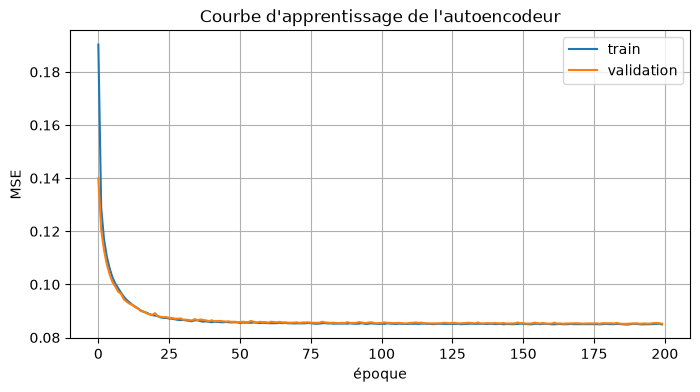

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(historique["train"], label="train")
plt.plot(historique["val"], label="validation")
plt.xlabel("époque")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage de l'autoencodeur")
plt.legend()
plt.grid()
plt.show()

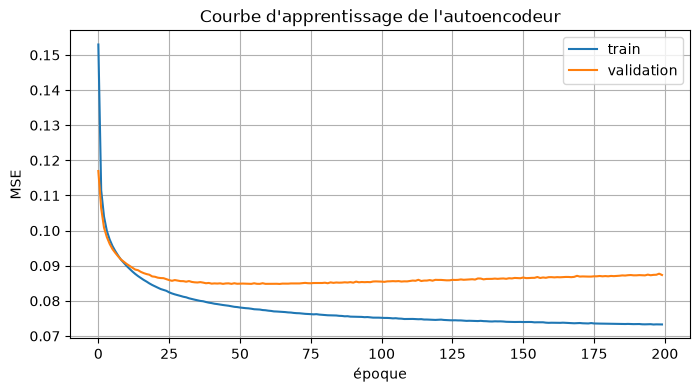

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(historique2["train"], label="train")
plt.plot(historique2["val"], label="validation")
plt.xlabel("époque")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage de l'autoencodeur")
plt.legend()
plt.grid()
plt.show()

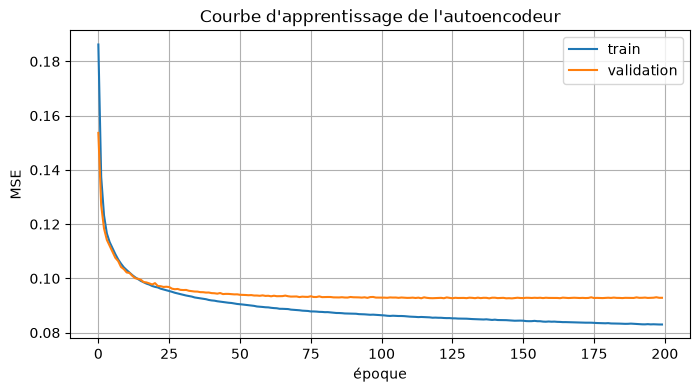

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(historique3["train"], label="train")
plt.plot(historique3["val"], label="validation")
plt.xlabel("époque")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage de l'autoencodeur")
plt.legend()
plt.grid()
plt.show()

In [20]:
import os
import numpy as np

os.makedirs("results", exist_ok=True)

np.savez_compressed(
    "results/resultats_AE.npz",

    # AE simple
    Z_train=res["Z_train"],
    Z_val=res["Z_val"],
    mse_train=res["mse_train"],
    mse_val=res["mse_val"],

    # AE profond
    Z_train_profond=res_couche["Z_train"],
    Z_val_profond=res_couche["Z_val"],
    mse_train_profond=res_couche["mse_train"],
    mse_val_profond=res_couche["mse_val"],
    Z_train_profond2=res_couche2["Z_train"],
    Z_val_profond2=res_couche2["Z_val"],
    mse_train_profond2=res_couche2["mse_train"],
    mse_val_profond2=res_couche2["mse_val"],

    # Historiques d'entraînement
    historique_train=historique["train"],
    historique_val=historique["val"],
    historique2_train=historique2["train"],
    historique2_val=historique2["val"],

    # Identification des cellules
    train_obs_names=train.obs_names.to_numpy(),
    val_obs_names=val.obs_names.to_numpy()
    
)

print("Résultats AE sauvegardés.")

Résultats AE sauvegardés.


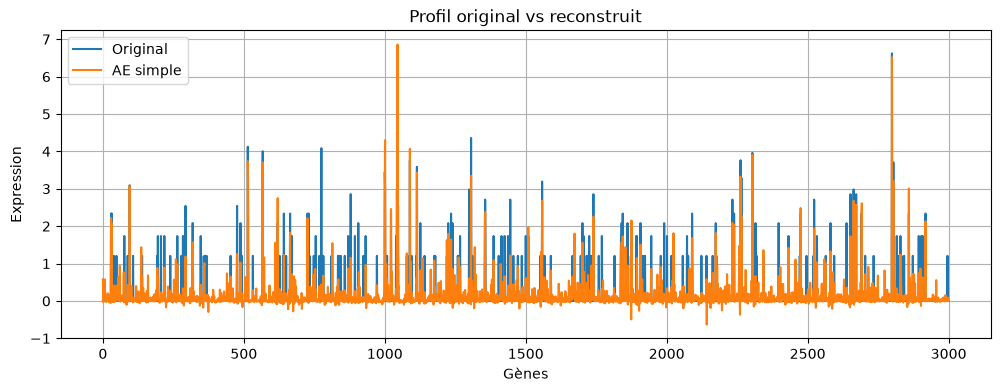

In [17]:
cellule = 0

plt.figure(figsize=(12, 4))

plt.plot(X_train[cellule], label="Original")
plt.plot(net(torch.tensor(X_train[cellule]).unsqueeze(0)).detach().numpy()[0],
         label="AE simple")

plt.xlabel("Gènes")
plt.ylabel("Expression")
plt.title("Profil original vs reconstruit")
plt.legend()
plt.grid()
plt.show()

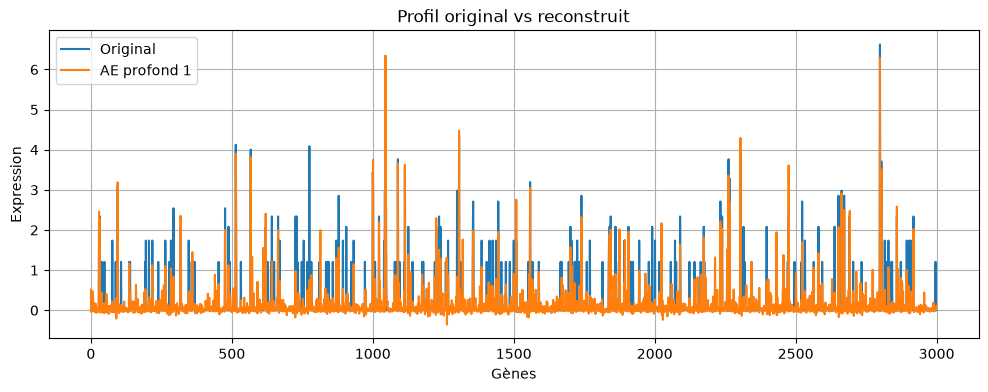

In [18]:
cellule = 0

plt.figure(figsize=(12, 4))

plt.plot(X_train[cellule], label="Original")
plt.plot(net_couche(torch.tensor(X_train[cellule]).unsqueeze(0)).detach().numpy()[0],
         label="AE profond 1")

plt.xlabel("Gènes")
plt.ylabel("Expression")
plt.title("Profil original vs reconstruit")
plt.legend()
plt.grid()
plt.show()

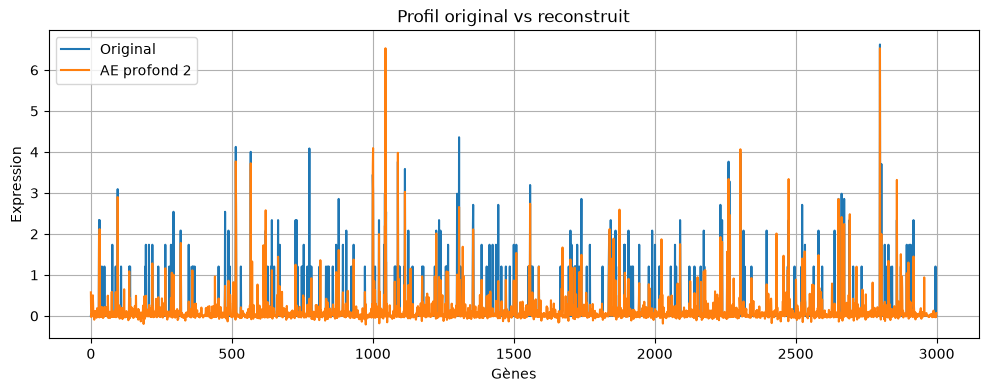

In [19]:
cellule = 0

plt.figure(figsize=(12, 4))

plt.plot(X_train[cellule], label="Original")
plt.plot(net_couche2(torch.tensor(X_train[cellule]).unsqueeze(0)).detach().numpy()[0],
         label="AE profond 2")

plt.xlabel("Gènes")
plt.ylabel("Expression")
plt.title("Profil original vs reconstruit")
plt.legend()
plt.grid()
plt.show()